Freeform GPT Features — EDA + XGBoost

1. Load & inspect freeform feature CSV
2. Sanity checks vs RDKit ground truth (side-by-side grid)
3. Cross-correlation heatmap: RDKit vs freeform GPT
4. Build feature matrix
5. XGBoost — exact same pipeline as `build_train.py`

**Only change the config cell when switching models.**

In [1]:
from IPython.display import display
import warnings, random
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve,
    f1_score, precision_score, recall_score, accuracy_score, matthews_corrcoef
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import xgboost as xgb

def find_data_dir():
    here = Path().resolve()
    for candidate in [here / "data", here.parent / "data"]:
        if (candidate / "prestwick_library_screened.tsv.gz").exists():
            return candidate
    raise FileNotFoundError(f"Cannot find data/ from {here}")

DATA_DIR   = find_data_dir()
RDKIT_PATH = DATA_DIR / "maier_chemdesc_representation.tsv"
PAIRS_FILE = DATA_DIR / "results" / "mole_plus_gpt41mini" / "compound_strain_pairs_with_features_mole_plus_gpt.csv"

# ── Change these two lines to switch models ────────────────────────────────────
FREEFORM_CSV = DATA_DIR / "gpt_generation_without_guidance" / "gpt_features5_gpt-5.1_freeform.csv"
MODEL_TAG    = "gpt-5.1-freeform"

OUT_DIR = DATA_DIR / "feature_matrix_gpt" / "freeform" / MODEL_TAG
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Freeform CSV : {FREEFORM_CSV}")
print(f"Output dir   : {OUT_DIR}")

Freeform CSV : D:\Hiwi\GPT+Mole\GPT+Mole\data\gpt_generation_without_guidance\gpt_features5_gpt-5.1_freeform.csv
Output dir   : D:\Hiwi\GPT+Mole\GPT+Mole\data\feature_matrix_gpt\freeform\gpt-5.1-freeform


## 1. Load & Inspect

In [2]:
raw = pd.read_csv(FREEFORM_CSV)
META_COLS    = {"prestwick_ID", "smiles_resolution", "input"}
feature_cols = [c for c in raw.columns if c not in META_COLS]

print(f"Shape        : {raw.shape}")
print(f"Feature cols : {feature_cols}")
raw.head(3)

Shape        : (1197, 512)
Feature cols : ['smiles_parsed_successfully', 'heavy_atom_count', 'atom_count_total', 'atom_count_c', 'atom_count_n', 'atom_count_o', 'atom_count_h_explicit', 'atom_count_h_implicit', 'atom_count_halogen', 'atom_count_f', 'atom_count_cl', 'atom_count_br', 'atom_count_i', 'ring_count', 'aromatic_ring_count', 'nonaromatic_ring_count', 'ring_atom_count', 'ring_bond_count', 'fused_ring_count', 'heteroaromatic_ring_count', 'heterocycle_ring_count', 'benzene_like_ring_count', 'five_membered_ring_count', 'six_membered_ring_count', 'largest_ring_size', 'smallest_ring_size', 'ring_fusion_degree', 'sp2_atom_count', 'sp3_atom_count', 'sp_atom_count', 'formal_charge_total', 'formal_charge_positive', 'formal_charge_negative', 'n_formal_charge_positive', 'n_formal_charge_negative', 'o_formal_charge_negative', 'heteroatom_count', 'heteroatom_fraction', 'n_heteroatoms', 'o_heteroatoms', 'h_bond_donor_count', 'h_bond_acceptor_count', 'h_bond_donor_nitrogen_count', 'h_bond_acc

,smiles_parsed_successfully,heavy_atom_count,atom_count_total,atom_count_c,atom_count_n,atom_count_o,atom_count_h_explicit,atom_count_h_implicit,atom_count_halogen,atom_count_f,...,qsar_gi_irritation_score,qsar_allergenic_potential_score,qsar_immunomodulatory_score,qsar_inflammation_modulation_score,qsar_microbiome_disruption_score,antimicrobial_feature_vector_dimension,input,prestwick_ID,smiles_resolution,intramolecular_hbond_likelihood_index
0,1,9,12,1,7,1,3,0,0,0,...,0.2,0.2,0.2,0.2,0.3,260,"{'query_smiles': 'Nc1nc2n[nH]nc2c(=O)[nH]1', '...",Prestw-1,fast,NaN
1,1,13,21,6,4,2,3,5,0,0,...,0.2,0.1,0.2,0.2,0.2,300,{'query_smiles': 'NC(N)=NS(=O)(=O)c1ccc(N)cc1'...,Prestw-10,fast,NaN
2,1,20,22,13,3,3,2,0,0,0,...,0.3,0.2,0.2,0.2,0.3,300,{'query_smiles': 'COC(=O)Nc1nc2ccc(C(=O)c3cccs...,Prestw-100,fast,NaN


In [3]:
print(pd.DataFrame({"dtype": raw[feature_cols].dtypes,
                     "nulls": raw[feature_cols].isnull().sum()}))
raw[feature_cols].describe().round(3)

                                          dtype  nulls
smiles_parsed_successfully                int64      0
heavy_atom_count                          int64      0
atom_count_total                          int64      0
atom_count_c                              int64      0
atom_count_n                              int64      0
...                                         ...    ...
qsar_immunomodulatory_score             float64      0
qsar_inflammation_modulation_score      float64      0
qsar_microbiome_disruption_score        float64      0
antimicrobial_feature_vector_dimension    int64      0
intramolecular_hbond_likelihood_index   float64   1142

[509 rows x 2 columns]


,smiles_parsed_successfully,heavy_atom_count,atom_count_total,atom_count_c,atom_count_n,atom_count_o,atom_count_h_explicit,atom_count_h_implicit,atom_count_halogen,atom_count_f,...,qsar_cyp_inhibition_score,qsar_hepatotoxicity_score,qsar_nephrotoxicity_score,qsar_gi_irritation_score,qsar_allergenic_potential_score,qsar_immunomodulatory_score,qsar_inflammation_modulation_score,qsar_microbiome_disruption_score,antimicrobial_feature_vector_dimension,intramolecular_hbond_likelihood_index
count,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,...,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.000,1197.00,1197.000,55.000
mean,0.987,21.758,33.947,16.487,2.062,3.020,1.888,10.290,0.457,0.155,...,0.233,0.239,0.159,0.199,0.126,0.153,0.153,0.20,295.048,0.162
std,0.111,10.609,18.615,9.260,1.802,2.939,3.553,8.598,1.048,0.591,...,0.079,0.078,0.067,0.075,0.061,0.076,0.076,0.08,34.182,0.080
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-1.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.00,0.000,0.000
25%,1.000,16.000,23.000,10.000,1.000,1.000,1.000,5.000,0.000,0.000,...,0.200,0.200,0.100,0.150,0.100,0.100,0.100,0.15,300.000,0.100
50%,1.000,20.000,30.000,16.000,2.000,2.000,1.000,9.000,0.000,0.000,...,0.200,0.200,0.200,0.200,0.100,0.100,0.100,0.20,300.000,0.200
75%,1.000,26.000,40.000,20.000,3.000,4.000,2.000,14.000,1.000,0.000,...,0.300,0.300,0.200,0.250,0.200,0.200,0.200,0.30,300.000,0.200
max,1.000,119.000,197.000,93.000,15.000,30.000,78.000,83.000,11.000,6.000,...,0.400,0.400,0.300,0.400,0.300,0.350,0.350,0.40,400.000,0.400


In [4]:
n, ncols = len(feature_cols), 4
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3))
axes = axes.flatten()
for i, col in enumerate(feature_cols):
    axes[i].hist(raw[col].dropna(), bins=40, color="#185FA5", alpha=0.75, edgecolor="none")
    axes[i].set_title(col, fontsize=8)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
fig.suptitle(f"Feature Distributions — {MODEL_TAG}", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Sanity Checks vs RDKit (Side-by-Side)

In [5]:
rdkit = pd.read_csv(RDKIT_PATH, sep="\t")

# GPT feature name -> closest RDKit column
SANITY_MAP = {
    "molecular_weight":               "MolWt",
    "num_hydrogen_bond_donors":       "NumHDonors",
    "num_hydrogen_bond_acceptors":    "NumHAcceptors",
    "num_aromatic_rings":             "NumAromaticRings",
    "num_rings":                      "NumRings",
    "topological_polar_surface_area": "TPSA",
    "fraction_csp3":                  "FractionCSP3",
    "num_rotatable_bonds":            "NumRotatableBonds",
}

valid_pairs = [(g, r) for g, r in SANITY_MAP.items()
               if g in raw.columns and r in rdkit.columns]
print(f"Sanity check pairs: {len(valid_pairs)}")
for g, r in valid_pairs:
    print(f"  {g:42s} -> {r}")

Sanity check pairs: 1
  molecular_weight                           -> MolWt


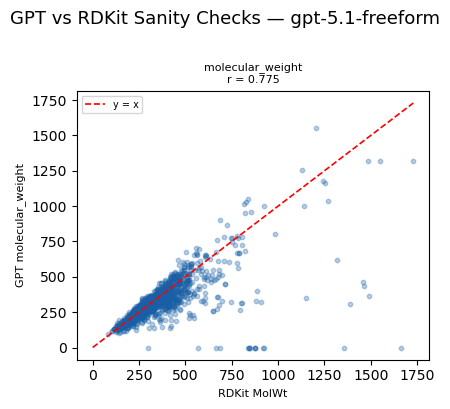

5 MOST SIMILAR (GPT ≈ RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-1207,180.159,180.157,-0.0
1,Prestw-17,197.190,197.190,-0.0
2,Prestw-338,281.272,281.270,-0.0
3,Prestw-411,290.447,290.450,0.0
4,Prestw-63,346.339,346.340,0.0



5 MOST OVERESTIMATED (GPT >> RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-435,1202.635,1555.0,352.36
1,Prestw-405,685.904,899.2,213.30
2,Prestw-854,837.058,1047.6,210.54
3,Prestw-154,828.006,1031.3,203.29
4,Prestw-36,813.979,1015.3,201.32



5 MOST UNDERESTIMATED (GPT << RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-522,1664.922,0.00,-1664.92
1,Prestw-433,1355.388,0.00,-1355.39
2,Prestw-160,1488.807,363.47,-1125.34
3,Prestw-506,1385.461,307.37,-1078.09
4,Prestw-159,1461.429,437.43,-1024.00


In [6]:
merged = raw[["prestwick_ID"] + [g for g, _ in valid_pairs]].merge(
    rdkit[["prestwick_ID"] + [r for _, r in valid_pairs]], on="prestwick_ID", how="inner"
)

n_pairs = len(valid_pairs)
ncols   = min(4, n_pairs)
nrows   = (n_pairs + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.5, nrows * 4))
axes = np.array(axes).flatten()

sanity_results = []
for i, (gpt_col, rdkit_col) in enumerate(valid_pairs):
    ax   = axes[i]
    x, y = merged[rdkit_col], merged[gpt_col]
    r, p  = spearmanr(x, y)
    sanity_results.append({"gpt": gpt_col, "rdkit": rdkit_col,
                            "spearman_r": round(r, 4), "p": round(p, 6)})
    ax.scatter(x, y, alpha=0.3, s=10, color="#185FA5", rasterized=True)
    mn, mx = min(x.min(), y.min()), max(x.max(), y.max())
    ax.plot([mn, mx], [mn, mx], "r--", lw=1.2, label="y = x")
    ax.set_xlabel(f"RDKit {rdkit_col}", fontsize=8)
    ax.set_ylabel(f"GPT {gpt_col}", fontsize=8)
    ax.set_title(f"{gpt_col}\nr = {r:.3f}", fontsize=8)
    ax.legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(f"GPT vs RDKit Sanity Checks — {MODEL_TAG}", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "sanity_checks.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Molecular weight deep-dive table ──────────────────────────────────────────
mw_gpt_col   = "molecular_weight"
mw_rdkit_col = "MolWt"

if mw_gpt_col in merged.columns and mw_rdkit_col in merged.columns:
    mw = merged[["prestwick_ID", mw_rdkit_col, mw_gpt_col]].copy()
    mw = mw.rename(columns={mw_rdkit_col: "rdkit_MolWt", mw_gpt_col: "gpt_MolWt"})
    mw["diff"]     = (mw["gpt_MolWt"] - mw["rdkit_MolWt"]).round(2)
    mw["abs_diff"] = mw["diff"].abs()

    closest   = mw.nsmallest(5, "abs_diff").reset_index(drop=True)
    overest   = mw.nlargest(5,  "diff").reset_index(drop=True)
    underest  = mw.nsmallest(5, "diff").reset_index(drop=True)

    print("5 MOST SIMILAR (GPT ≈ RDKit):")
    display(closest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

    print("\n5 MOST OVERESTIMATED (GPT >> RDKit):")
    display(overest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

    print("\n5 MOST UNDERESTIMATED (GPT << RDKit):")
    display(underest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

## 3. Cross-Correlation: RDKit vs Freeform GPT

In [7]:
rdkit_al = (rdkit.set_index("prestwick_ID")
                .apply(pd.to_numeric, errors="coerce").fillna(0))
rdkit_al = rdkit_al.loc[:, rdkit_al.std() > 1e-6]

gpt_al = (raw.set_index("prestwick_ID")[feature_cols]
             .apply(pd.to_numeric, errors="coerce").fillna(0))
gpt_al = gpt_al.loc[:, gpt_al.std() > 1e-6]

common   = rdkit_al.index.intersection(gpt_al.index)
rdkit_al = rdkit_al.loc[common].sort_index()
gpt_al   = gpt_al.loc[common].sort_index()

rdkit_al.columns = ["rdkit__" + c for c in rdkit_al.columns]
gpt_al.columns   = ["gpt__"   + c for c in gpt_al.columns]

n_rdkit, n_gpt = rdkit_al.shape[1], gpt_al.shape[1]
print(f"RDKit: {n_rdkit} features  |  GPT freeform: {n_gpt} features")

# Compute only the GPT × RDKit cross-correlation block
combined_all = pd.concat([rdkit_al, gpt_al], axis=1)
full_corr    = combined_all.corr(method="spearman")
corr_sp      = full_corr   # keep for novelty cell downstream

rdkit_cols_idx = [c for c in full_corr.columns if c.startswith("rdkit__")]
gpt_cols_idx   = [c for c in full_corr.columns if c.startswith("gpt__")]
cross_block    = full_corr.loc[gpt_cols_idx, rdkit_cols_idx]

# Clean axis labels (remove prefixes)
cross_block.index   = [c.replace("gpt__", "")   for c in cross_block.index]
cross_block.columns = [c.replace("rdkit__", "") for c in cross_block.columns]

fig, ax = plt.subplots(figsize=(max(20, n_rdkit * 0.22), max(4, n_gpt * 0.55)))
sns.heatmap(cross_block, cmap="coolwarm", center=0, annot=(n_gpt <= 30),
            fmt=".2f", linewidths=0.3, rasterized=True, ax=ax)
ax.set_title(f"Cross-Correlation: GPT freeform vs RDKit (Spearman) — {MODEL_TAG}", fontsize=12)
ax.set_xlabel("RDKit features", fontsize=10)
ax.set_ylabel("GPT freeform features", fontsize=10)
plt.xticks(rotation=45, ha="right", fontsize=7)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "cross_corr_gpt_vs_rdkit.png", dpi=150, bbox_inches="tight")
plt.show()

RDKit: 96 features  |  GPT freeform: 508 features


In [8]:
corr_self  = gpt_al.corr(method="spearman")
gpt_labels = [c.replace("gpt__", "") for c in gpt_al.columns]

fig, ax = plt.subplots(figsize=(max(8, n_gpt), max(7, n_gpt - 1)))
sns.heatmap(corr_self, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            xticklabels=gpt_labels, yticklabels=gpt_labels, linewidths=0.4, ax=ax)
ax.set_title(f"GPT Feature Self-Correlation (Spearman) — {MODEL_TAG}", fontsize=11)
plt.tight_layout()
plt.savefig(OUT_DIR / "self_corr.png", dpi=150, bbox_inches="tight")
plt.show()

MemoryError: bad allocation

MemoryError: 

<Figure size 50800x50700 with 2 Axes>

In [ ]:
rdkit_cols_list = [c for c in corr_sp.columns if c.startswith("rdkit__")]
gpt_cols_list   = [c for c in corr_sp.columns if c.startswith("gpt__")]

novelty = []
for g in gpt_cols_list:
    row = corr_sp.loc[g, rdkit_cols_list].abs()
    novelty.append({"gpt_feature": g.replace("gpt__", ""),
                    "max_r_vs_rdkit": float(row.max()),
                    "closest_rdkit": row.idxmax().replace("rdkit__", "")})

nov_df = pd.DataFrame(novelty).sort_values("max_r_vs_rdkit", ascending=True)

fig, ax = plt.subplots(figsize=(8, max(3, len(nov_df) * 0.6)))
colors  = ["#A32D2D" if r > 0.6 else "#D85A30" for r in nov_df["max_r_vs_rdkit"]]
bars    = ax.barh(nov_df["gpt_feature"], nov_df["max_r_vs_rdkit"], color=colors, height=0.55)
ax.axvline(0.6, color="red",    linestyle="--", lw=1.2, label="0.6 high corr")
ax.axvline(0.4, color="orange", linestyle="--", lw=1.2, label="0.4 moderate")
for bar, val in zip(bars, nov_df["max_r_vs_rdkit"]):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", fontsize=8)
ax.set_xlabel("Max |Spearman| vs any RDKit feature")
ax.set_title(f"GPT Feature Novelty vs RDKit — {MODEL_TAG}\nlower bar = more novel")
ax.legend(fontsize=8)
ax.set_xlim(0, 1.12)
plt.tight_layout()
plt.savefig(OUT_DIR / "novelty_bar.png", dpi=150, bbox_inches="tight")
plt.show()
nov_df

## 4. Build Feature Matrix

In [ ]:
feat_df = raw[["prestwick_ID"] + feature_cols].copy()
for col in feature_cols:
    feat_df[col] = pd.to_numeric(feat_df[col], errors="coerce").fillna(0)

keep    = [c for c in feature_cols if feat_df[c].std() > 1e-6]
dropped = [c for c in feature_cols if c not in keep]
if dropped:
    print(f"Dropped zero-variance: {dropped}")
feat_df = feat_df[["prestwick_ID"] + keep]
print(f"Feature matrix: {feat_df.shape}  ({len(feature_cols)} -> {len(keep)} features)")

In [ ]:
pairs = pd.read_csv(PAIRS_FILE, usecols=["prestwick_ID", "bacterium", "label", "split"])
print(f"Pairs: {pairs.shape}  |  label dist: {pairs['label'].value_counts().to_dict()}")

df = pairs.merge(feat_df, on="prestwick_ID", how="inner")
missing = set(pairs["prestwick_ID"]) - set(feat_df["prestwick_ID"])
print(f"After merge: {df.shape}  |  unmatched compounds: {len(missing)}")